# MAE MPC · One-step objective weights

How much of the realized one-step cost comes from reconstruction loss and how much comes from RankMe? The first figure shows this breakdown across the weight sweep. We replay **384 held-out decisions** on the Phase 1.2 walks (128 per seed). At each recorded state, the candidate actions are Skip, Quarter LR and Full LR. A forecast selects the action. Paired measurements from that state tell us its immediate effect.

The O3 controller minimizes current-image reconstruction loss and rewards higher RankMe. For the one-step sweep, let $\rho$ be the RankMe share of the two coefficients. For action $a$, the change in cost relative to Skip is

$$\Delta J_\rho(a)=(1-\rho)\,\Delta L(a)/s_L-\rho\,\Delta R(a)/s_R.$$

Here $\Delta$ means **action minus Skip** on the same frame. $R$ is RankMe on a fixed bank of 128 images. The scales are the original per-seed calibration standard deviations used by O3. Its coefficients of 1 for loss and 0.25 for rank correspond to **$\rho=0.20$**, with the same action ordering. A 20% coefficient share does not imply that RankMe accounts for 20% of the realized cost.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

# Edit these shares and rerun. The endpoints and O3 reference are always included.
rank_shares = np.linspace(0, 1, 101)
reference_share = 0.20
shares = np.unique(np.r_[0., reference_share, rank_shares, 1.])
if not (np.isfinite(shares).all() and np.all((shares >= 0) & (shares <= 1))):
    raise ValueError("RankMe shares must be between zero and one.")

# Run from the workspace or any subdirectory. Set data_dir directly for a copied archive.
archive_path = Path("analysis/2026-11-09-one-step-mpc/mae-p12-online16/direct-o3-targets/pilot-2048")
data_dir = next((p / archive_path for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / archive_path / "design.json").is_file()), None)
if data_dir is None:
    raise FileNotFoundError(f"Expected the local paired-rollout archive at {archive_path}")

design = json.loads((data_dir / "design.json").read_text())
one_step = design["horizons"].index(1)
actions = ["Skip", "Quarter LR", "Full LR"]
# Loss and RankMe entries (0 and 2) of results/{seed}-cal/done.pt ['scale'].
scales = {
    2026: (0.1123883577353172, 1.160716163378144),
    2027: (0.11221647762689096, 1.438381926091792),
    2028: (0.1119263646862571, 1.1191553655753559),
}

### How each decision is replayed

We reproduce the pilot’s one-step component MLP (first initialization). It learns the loss and rank effects of Quarter LR and Full LR on 1,123 earlier calibration states per seed. At each audit state it forecasts both effects, then receives that state's measured outcomes before the next audit. Skip has zero effect by definition. All weights use the same forecasts, frames, masks and branches. Changing the weight only changes which branch is scored as best.

The checks below reproduce the archived one-step O3 scores for both forecasts and measurements before sweeping weights. The experiment code is in `mae-p12-online16/run_direct_o3_targets.py`; the O3 metric indices and coefficients are in `engine.py` in the parent experiment directory.

In [2]:
def one_step_forecasts(cal_x, cal_y, x, y, seed):
    scaler = StandardScaler().fit(cal_x)
    features = np.clip(scaler.transform(x), -5, 5)
    units = np.maximum(cal_y.std(axis=0), 1e-8)
    model = MLPRegressor(hidden_layer_sizes=(48, 24), max_iter=60, batch_size=256,
                         n_iter_no_change=8, alpha=.001, random_state=seed)
    with threadpool_limits(1), warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=ConvergenceWarning)
        model.fit(np.clip(scaler.transform(cal_x), -5, 5), (cal_y / units).reshape(len(cal_x), -1))
        model.batch_size = 1
        forecasts = []
        for row, measured in zip(features, y):
            forecasts.append(model.predict(row[None, :]).reshape(2, 2) * units)
            model.partial_fit(row[None, :], (measured / units).reshape(1, -1))
    return np.stack(forecasts)


def with_skip(values):
    return np.concatenate([np.zeros_like(values[:, :1]), values], axis=1)


skip_levels = pd.read_csv(data_dir / "one-step-skip-levels.csv").set_index(["seed", "origin"])
assert skip_levels.index.is_unique
runs = {}
for seed in design["seeds"]:
    with np.load(data_dir / f"{seed}-labels.npz", allow_pickle=False) as data:
        origins = data["origins"]
        measured = data["y"][one_step]  # origin × non-skip action × (loss, rank)
        assert np.all(np.diff(origins) > 0) and origins.min() >= design["calibration"]
        predicted = one_step_forecasts(data["cal_x"], data["cal_y"][one_step],
                                       data["x"], measured, seed)
    receipt = json.loads((data_dir / f"{seed}-forecasts.json").read_text())
    np.testing.assert_array_equal(origins, receipt["origins"])
    archived = next(row for row in receipt["data"] if row["horizon"] == 1)
    coef = np.array([1., -.25]) / scales[seed]
    np.testing.assert_allclose(measured @ coef, archived["objective"], atol=1e-9)
    np.testing.assert_allclose(predicted @ coef, np.asarray(archived["composed"])[0, 1], atol=1e-7)
    assert np.isfinite(predicted).all() and np.isfinite(measured).all()
    baseline = skip_levels.loc[seed].loc[origins, ["skip_loss", "skip_rank"]].to_numpy()
    assert np.isfinite(baseline).all() and (baseline > 0).all()
    runs[seed] = with_skip(predicted), with_skip(measured), baseline
print(f"Verified one-step O3 forecasts and paired measurements for {sum(len(v[0]) for v in runs.values())} decisions.")

Verified one-step O3 forecasts and paired measurements for 384 decisions.


In [3]:
rows = []
for seed, (predicted, measured, baseline) in runs.items():
    normalized = predicted / scales[seed]
    ref = (normalized[..., 0] - .25 * normalized[..., 1]).argmin(axis=1)
    for share in shares:
        # argmin resolves exact ties in action order (Skip, Quarter LR, Full LR).
        weights = np.array([1 - share, -share])
        choice = (normalized @ weights).argmin(axis=1)
        selected = measured[np.arange(len(choice)), choice]
        loss, rank = selected.mean(axis=0)
        changes = selected / scales[seed] * weights
        levels = (baseline + selected) / scales[seed] * weights
        loss_term, rank_term = changes.mean(axis=0)
        loss_abs_change, rank_abs_change = np.abs(changes).mean(axis=0)
        loss_level, rank_level = levels.mean(axis=0)
        np.testing.assert_allclose(levels - baseline / scales[seed] * weights, changes, atol=1e-12)
        skip, quarter, full = np.bincount(choice, minlength=3) / len(choice)
        rows.append(dict(seed=seed, share=share, loss=loss, rank=rank, loss_term=loss_term,
                         loss_level=loss_level, rank_level=rank_level, net_level=levels.sum(axis=1).mean(),
                         loss_abs_change=loss_abs_change, rank_abs_change=rank_abs_change,
                         rank_term=rank_term, cost=loss_term + rank_term, skip=skip,
                         quarter=quarter, full=full, changed=np.mean(choice != ref)))
per_seed = pd.DataFrame(rows)
mean = per_seed.groupby("share").mean(numeric_only=True).drop(columns="seed")
np.testing.assert_allclose(mean[["skip", "quarter", "full"]].sum(axis=1), 1.)
assert mean.loc[reference_share, "changed"] == 0.

# Ratios of pooled components, with equal weight per seed.
gross_level = mean.loss_level.abs() + mean.rank_level.abs()
gross_change = mean.loss_abs_change + mean.rank_abs_change
mean["rank_level_share"] = mean.rank_level.abs() / gross_level.where(gross_level > 0)
mean["loss_level_share"] = mean.loss_level.abs() / gross_level.where(gross_level > 0)
mean["rank_change_share"] = mean.rank_abs_change / gross_change.where(gross_change > 0)
mean["loss_change_share"] = mean.loss_abs_change / gross_change.where(gross_change > 0)
np.testing.assert_allclose(mean.loss_level + mean.rank_level, mean.net_level, atol=1e-12)
for cols in [("loss_level_share", "rank_level_share"), ("loss_change_share", "rank_change_share")]:
    valid = mean[list(cols)].dropna()
    np.testing.assert_allclose(valid.sum(axis=1), 1.)
landmarks = [0, reference_share, .5, .75, 1]
selected_shares = sorted({shares[np.abs(shares - value).argmin()] for value in landmarks})


### How much of the realized cost comes from each component?

For the selected action, the two **signed terms** are $C_L=(1-\rho)L/s_L$ and $C_R=-\rho R/s_R$. The left panel adds the measured terms to give the net cost $J$. The right panel shows each term’s **share of total magnitude**. For example, RankMe’s share is $\sum|C_R|/(\sum|C_L|+\sum|C_R|)$. That denominator stays meaningful even where the signed terms cancel and net cost crosses zero. The diagonal marks where the realized RankMe share would equal its coefficient share.

The solid teal curve answers how much RankMe contributes to the **level** of the cost. The dashed curve applies the same magnitude calculation to action-minus-Skip differences at each decision, showing how much RankMe contributes to the **change** in cost. Absolute values are taken before averaging those changes. Each seed receives equal weight.

The first table also divides each signed term by net cost. These percentages sum to 100%. A negative share means that component offsets the net result. When the net is zero its signed shares are undefined.

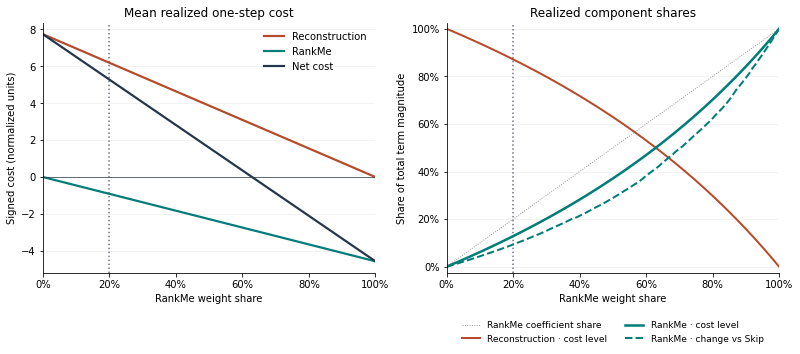

In [4]:
loss_color, rank_color, ink = "#B74A29", "#007D78", "#25364B"
def weight_axis(ax):
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel("RankMe weight share")
    ax.axvline(reference_share, color="#687384", linestyle=":", linewidth=1.5)
    ax.grid(axis="y", alpha=.18)
    ax.spines[["right", "top"]].set_visible(False)

fig, (level_ax, share_ax) = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)
for ax in (level_ax, share_ax):
    weight_axis(ax)
for name, label, color in [("loss_level", "Reconstruction", loss_color),
                           ("rank_level", "RankMe", rank_color), ("net_level", "Net cost", ink)]:
    level_ax.plot(mean.index, mean[name], color=color, label=label, lw=2.2)
level_ax.axhline(0, color=ink, linewidth=.7)
level_ax.set(title="Mean realized one-step cost", ylabel="Signed cost (normalized units)")
level_ax.legend(frameon=False)

share_ax.plot([0, 1], [0, 1], color="#888888", lw=.9, ls=":", label="RankMe coefficient share")
share_ax.plot(mean.index, mean.loss_level_share, color=loss_color, lw=2, label="Reconstruction · cost level")
share_ax.plot(mean.index, mean.rank_level_share, color=rank_color, lw=2.5, label="RankMe · cost level")
share_ax.plot(mean.index, mean.rank_change_share, color=rank_color, ls="--", lw=2, label="RankMe · change vs Skip")
share_ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
share_ax.set(title="Realized component shares", ylabel="Share of total term magnitude", ylim=(-.025, 1.025))
share_ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(.5, -.16), ncol=2)
plt.show()

In [5]:
points = mean.loc[selected_shares].copy()
# A signed share of net cost can exceed 100% when the other component offsets it.
net = points.net_level.where(points.net_level.abs() > 1e-10 * (points.loss_level.abs() + points.rank_level.abs()))
points["loss_net_share"] = points.loss_level / net
points["rank_net_share"] = points.rank_level / net
valid = points[["loss_net_share", "rank_net_share"]].dropna()
np.testing.assert_allclose(valid.sum(axis=1), 1.)
points.index = [f"{1-share:.0%} / {share:.0%}" for share in points.index]
points.index.name = "Loss / RankMe weights"

signed = points[["loss_level", "rank_level", "net_level", "loss_net_share", "rank_net_share"]].copy()
signed.columns = ["Loss term", "RankMe term", "Net cost", "Loss / net", "RankMe / net"]
display(signed.style.set_caption("Signed contributions to the mean realized one-step cost")
        .format({c: ("{:+.1%}" if "/ net" in c else "{:+.3f}") for c in signed}, na_rep="Undefined"))

magnitude = points[["loss_level_share", "rank_level_share", "loss_change_share", "rank_change_share"]].copy()
magnitude.columns = ["Loss · cost level", "RankMe · cost level", "Loss · change vs Skip", "RankMe · change vs Skip"]
display(magnitude.style.set_caption("Shares of total component magnitude")
        .format("{:.1%}", na_rep="Undefined"))


,Loss term,RankMe term,Net cost,Loss / net,RankMe / net
Loss / RankMe weights,,,,,
100% / 0%,+7.743,+0.000,+7.743,+100.0%,+0.0%
80% / 20%,+6.194,-0.913,+5.281,+117.3%,-17.3%
50% / 50%,+3.872,-2.283,+1.589,+243.7%,-143.7%
25% / 75%,+1.937,-3.426,-1.489,-130.1%,+230.1%
0% / 100%,+0.000,-4.568,-4.568,-0.0%,+100.0%


,Loss · cost level,RankMe · cost level,Loss · change vs Skip,RankMe · change vs Skip
Loss / RankMe weights,,,,
100% / 0%,100.0%,0.0%,100.0%,0.0%
80% / 20%,87.2%,12.8%,90.7%,9.3%
50% / 50%,62.9%,37.1%,71.1%,28.9%
25% / 75%,36.1%,63.9%,44.3%,55.7%
0% / 100%,0.0%,100.0%,0.0%,100.0%


### What happens to the two measured outcomes?

Each point averages the measured, one-step effect of the forecast-selected action relative to Skip. Below zero favors reconstruction in the left panel. Above zero favors RankMe in the right panel. Thin lines show individual seeds and the bold line gives each seed equal weight.

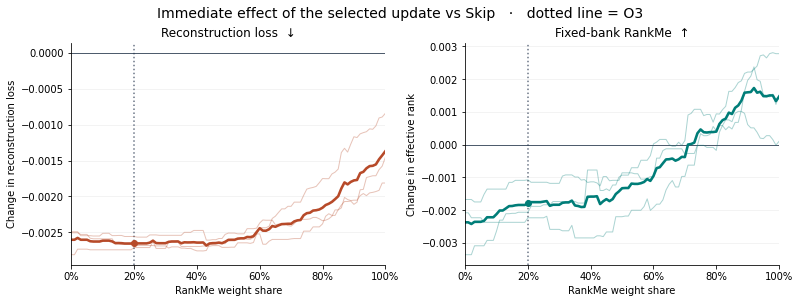

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), constrained_layout=True)
for ax, metric, title, unit, color in zip(
        axes, ["loss", "rank"], ["Reconstruction loss  ↓", "Fixed-bank RankMe  ↑"],
        ["Change in reconstruction loss", "Change in effective rank"], [loss_color, rank_color]):
    weight_axis(ax)
    ax.axhline(0, color=ink, linewidth=.8)
    for _, group in per_seed.groupby("seed"):
        ax.plot(group.share, group[metric], color=color, alpha=.33, linewidth=1)
    ax.plot(mean.index, mean[metric], color=color, linewidth=2.6)
    ax.scatter(reference_share, mean.loc[reference_share, metric], color=color, zorder=4)
    ax.set(title=title, ylabel=unit)
fig.suptitle("Immediate effect of the selected update vs Skip   ·   dotted line = O3", fontsize=14)
plt.show()

### How do the selected actions change cost relative to Skip?

The left panel decomposes measured cost into its two signed terms. Negative values improve the objective relative to Skip. A lower cost across two different weights uses a different scoring rule, so use the raw outcomes above to compare trade-offs. The right panel shows how often the forecast selects each learning rate.

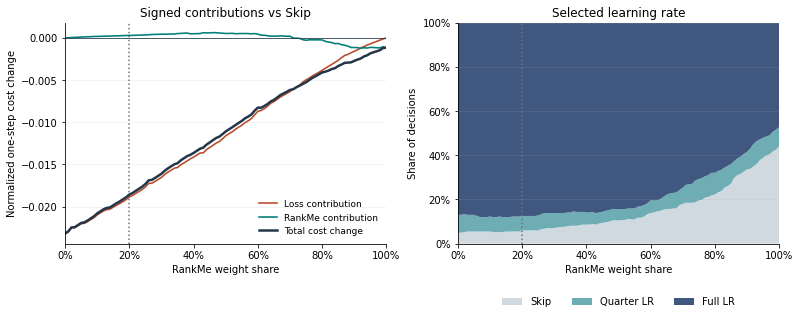

In [7]:
fig, (cost_ax, action_ax) = plt.subplots(1, 2, figsize=(11, 4.3), constrained_layout=True)
for ax in (cost_ax, action_ax):
    weight_axis(ax)
for column, label, color in [("loss_term", "Loss contribution", loss_color),
                             ("rank_term", "RankMe contribution", rank_color),
                             ("cost", "Total cost change", ink)]:
    cost_ax.plot(mean.index, mean[column], label=label, color=color,
                 linewidth=2.5 if column == "cost" else 1.6)
cost_ax.axhline(0, color=ink, linewidth=.8)
cost_ax.set(title="Signed contributions vs Skip", ylabel="Normalized one-step cost change")
cost_ax.legend(frameon=False, fontsize=9)
action_ax.stackplot(mean.index.to_numpy(), *mean[["skip", "quarter", "full"]].to_numpy().T,
                    labels=actions, colors=["#CED6DF", "#66A9B0", "#364F78"], alpha=.95)
action_ax.set(title="Selected learning rate", ylabel="Share of decisions", ylim=(0, 1))
action_ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
action_ax.legend(loc="upper center", bbox_to_anchor=(.5, -.2), ncol=3, frameon=False)
plt.show()

### Selected operating points

The table compares representative settings, including the reference and both single-metric objectives. “Changed vs O3” counts paired decisions that selected a different action. The replay estimates immediate consequences at the recorded states. Longer-run training trajectories and downstream task accuracy require separate experiments.

In [8]:
table = mean.loc[selected_shares, ["loss", "rank", "cost", "skip", "quarter", "full", "changed"]].copy()
table.insert(0, "Loss wt.", 1 - table.index)
table.insert(1, "RankMe wt.", table.index)
table.columns = ["Loss wt.", "RankMe wt.", "Δ loss", "Δ RankMe", "Δ cost", *actions, "Changed vs O3"]
for column in ["Loss wt.", "RankMe wt.", *actions, "Changed vs O3"]:
    table[column] = table[column].map("{:.1%}".format)
display(table.reset_index(drop=True).style.format({k: "{:+.5f}" for k in ["Δ loss", "Δ RankMe", "Δ cost"]})
        .hide(axis="index"))

Loss wt.,RankMe wt.,Δ loss,Δ RankMe,Δ cost,Skip,Quarter LR,Full LR,Changed vs O3
100.0%,0.0%,-0.00260,-0.00238,-0.02320,4.9%,8.1%,87.0%,4.4%
80.0%,20.0%,-0.00265,-0.00179,-0.01858,6.0%,6.5%,87.5%,0.0%
50.0%,50.0%,-0.00260,-0.00133,-0.01109,10.4%,5.2%,84.4%,10.7%
25.0%,75.0%,-0.00223,+0.00046,-0.00526,19.5%,9.6%,70.8%,28.4%
0.0%,100.0%,-0.00137,+0.00146,-0.00118,44.0%,8.6%,47.4%,53.9%


**Measurement source.** The one-step labels archive stores each candidate’s differences from Skip. The companion `one-step-skip-levels.csv` supplies the two absolute Skip readings for each (seed, origin). They were recovered by replaying the archived action trace from each calibration checkpoint, evaluating the current frame with the original mask seed and computing RankMe on that seed’s Fixed-128 bank. At audited states where the trace took an update, its measured post-update difference was checked against the archived branch. Adding the matched Skip readings to each selected branch recovers its absolute loss and RankMe.